In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [2]:
def bisection(f, a, b, tol=1e-12, max_iter=100):
    #Finds a root of f(x) = 0 on [a, b] using the Bisection method.
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("Root must be bracketed: f(a) and f(b) must have opposite signs.")
    if fa == 0.0:
        return a, 0
    if fb == 0.0:
        return b, 0

    #stores all of the values
    history = []
    for i in range(max_iter):
        c = 0.5 * (a + b)
        fc = f(c)
        history.append(c)
        
        if abs(fc) < tol or 0.5 * (b - a) < tol:
            break
            
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
            
    return c, np.array(history)


def newton_bracketed(f, df, a, b, x0=None, tol=1e-12, max_iter=100):
    #bracketed Newton-Raphson method
    # takes a newton step if its within the bracket, if it's not, it takes a Bisection step.
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("Root must be bracketed: f(a) and f(b) must have opposite signs.")
    if fa == 0.0:
        return a, np.array([a])
    if fb == 0.0:
        return b, np.array([b])

    # Orient the search so that f(xl) < 0 and f(xh) > 0
    if fa < 0.0:
        xl, xh = a, b
    else:
        xl, xh = b, a

    rts = 0.5 * (a + b) if x0 is None else x0
    dxold = abs(b - a)
    dx = dxold
    f_val = f(rts)
    df_val = df(rts)
    history = [rts]

    # go through each value
    for i in range(max_iter):
        # bisect if Newton step jumps out of bracket or is not decreasing fast enough
        out_of_bounds = ((rts - xh) * df_val - f_val) * ((rts - xl) * df_val - f_val) > 0.0
        too_slow = abs(2.0 * f_val) > abs(dxold * df_val)

        if out_of_bounds or too_slow:
            dxold = dx
            dx = 0.5 * (xh - xl)
            rts = xl + dx
            if xl == rts:  # machine precision limit reached
                history.append(rts)
                break
        else:
            dxold = dx
            dx = f_val / df_val
            temp = rts
            rts -= dx
            if temp == rts:
                history.append(rts)
                break

        history.append(rts)
        if abs(dx) < tol:
            break

        f_val = f(rts)
        df_val = df(rts)
        
        # maintain bracket
        if f_val < 0.0:
            xl = rts
        else:
            xh = rts

    return rts, np.array(history)

In [3]:
# test the programs

# (a) x^2 = 2.0  =>  f(x) = x^2 - 2.0 = 0
f_sq = lambda x: x**2 - 2.0
df_sq = lambda x: 2.0 * x
true_sq = math.sqrt(2.0)

root_sq_b, hist_sq_b = bisection(f_sq, 0.0, 2.0)
root_sq_n, hist_sq_n = newton_bracketed(f_sq, df_sq, 0.0, 2.0, x0=1.0)

# (b1) Kepler's Equation: M = E - e*sin(E) => f(E) = E - e*sin(E) - M = 0 (M=1.5, e=0.5)
M = 1.5
e1 = 0.5
f_kep1 = lambda E: E - e1 * math.sin(E) - M
df_kep1 = lambda E: 1.0 - e1 * math.cos(E)

root_k1_b, hist_k1_b = bisection(f_kep1, 0.0, 2.0 * math.pi)
root_k1_n, hist_k1_n = newton_bracketed(f_kep1, df_kep1, 0.0, 2.0 * math.pi, x0=M)

# (b2) Kepler's Equation: M=1.5, e=0.9 (High eccentricity)
e2 = 0.9
f_kep2 = lambda E: E - e2 * math.sin(E) - M
df_kep2 = lambda E: 1.0 - e2 * math.cos(E)

root_k2_b, hist_k2_b = bisection(f_kep2, 0.0, 2.0 * math.pi)
# starting at E0 = pi (or E0 = M + e*sin(M)) avoids small derivative near E = 0
root_k2_n, hist_k2_n = newton_bracketed(f_kep2, df_kep2, 0.0, 2.0 * math.pi, x0=math.pi)

# Print Summary Results
print(f"(a) sqrt(2):      True = {true_sq:.15f} | Bisection = {root_sq_b:.15f} ({len(hist_sq_b)} iters) | Safe NR = {root_sq_n:.15f} ({len(hist_sq_n)} iters)")
print(f"(b1) Kepler e=0.5: Ref  = {root_k1_n:.15f} | Bisection = {root_k1_b:.15f} ({len(hist_k1_b)} iters) | Safe NR = {root_k1_n:.15f} ({len(hist_k1_n)} iters)")
print(f"(b2) Kepler e=0.9: Ref  = {root_k2_n:.15f} | Bisection = {root_k2_b:.15f} ({len(hist_k2_b)} iters) | Safe NR = {root_k2_n:.15f} ({len(hist_k2_n)} iters)")

(a) sqrt(2):      True = 1.414213562373095 | Bisection = 1.414213562373334 (39 iters) | Safe NR = 1.414213562373095 (7 iters)
(b1) Kepler e=0.5: Ref  = 1.962189287578571 | Bisection = 1.962189287578441 (42 iters) | Safe NR = 1.962189287578571 (6 iters)
(b2) Kepler e=0.9: Ref  = 2.217997202598577 | Bisection = 2.217997202599177 (42 iters) | Safe NR = 2.217997202598577 (6 iters)


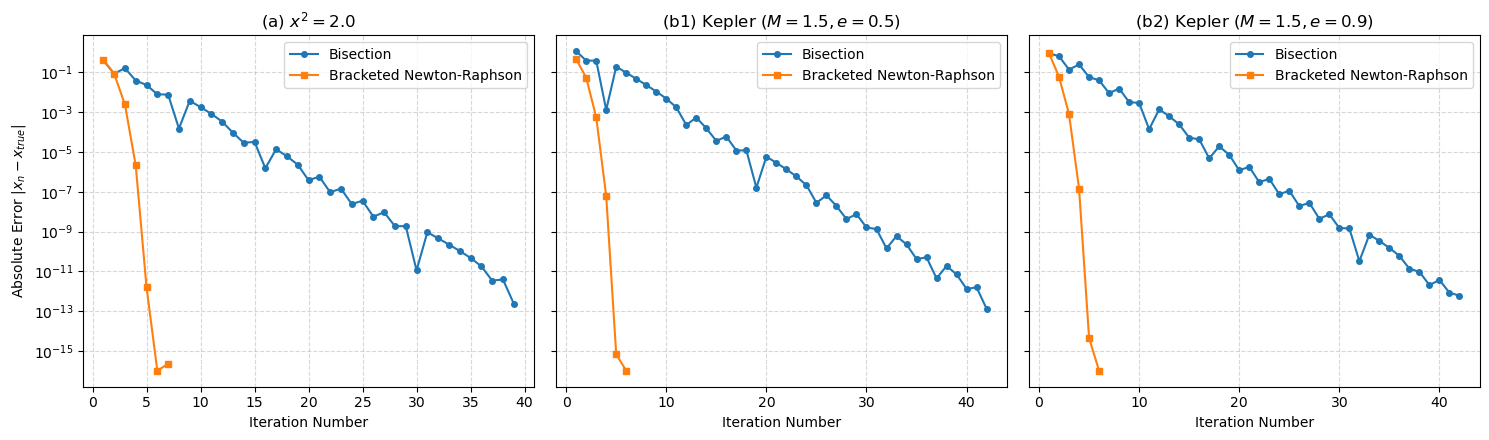

In [4]:
# plot the errors
cases = [
    ("(a) $x^2 = 2.0$", hist_sq_b, hist_sq_n, true_sq),
    ("(b1) Kepler ($M=1.5, e=0.5$)", hist_k1_b, hist_k1_n, root_k1_n),
    ("(b2) Kepler ($M=1.5, e=0.9$)", hist_k2_b, hist_k2_n, root_k2_n),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# actually show the graphs
for ax, (title, h_b, h_n, true_val) in zip(axes, cases):
    # Add small floor (1e-16) so exact float matches display cleanly on log axis
    err_b = np.maximum(np.abs(h_b - true_val), 1e-16)
    err_n = np.maximum(np.abs(h_n - true_val), 1e-16)
    
    ax.semilogy(range(1, len(err_b) + 1), err_b, 'o-', markersize=4, label='Bisection')
    ax.semilogy(range(1, len(err_n) + 1), err_n, 's-', markersize=5, label='Bracketed Newton-Raphson')
    ax.set_title(title)
    ax.set_xlabel("Iteration Number")
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.legend()

axes[0].set_ylabel("Absolute Error $|x_n - x_{true}|$")
plt.tight_layout()
plt.show()

In [5]:
e = 0.9
M_vals = np.linspace(0, 2 * np.pi, 10000)

# finding wall clock time for Bisection program
t0 = time.perf_counter()
E_bis = np.empty_like(M_vals)
for idx, M in enumerate(M_vals):
    f = lambda E: E - e * np.sin(E) - M
    E_bis[idx], _ = bisection(f, 0.0, 2 * np.pi)
t_bis = time.perf_counter() - t0

# wall clock time for Bracketed Newton-Raphson program
t0 = time.perf_counter()
E_newt = np.empty_like(M_vals)
for idx, M in enumerate(M_vals):
    f = lambda E: E - e * np.sin(E) - M
    df = lambda E: 1.0 - e * np.cos(E)
    E_newt[idx], _ = newton_bracketed(f, df, 0.0, 2 * np.pi)
t_newt = time.perf_counter() - t0

print(f"Bisection: {t_bis:.4f} s | Newton: {t_newt:.4f} s | Speedup: {t_bis / t_newt:.2f}x")

Bisection: 0.3856 s | Newton: 0.1144 s | Speedup: 3.37x


Newton-raphson's total opperations are significantly less than the Bisection programs, which makes up for any extra cost in the actual computations run. Additionally, newton-raphson converges quadraticlly, while bisection converges linearly, which means the newton-raphson overall more accurate due to the way it converges than bisection.

In [6]:
# planck cosmological constants
Omega_M = 0.321
Omega_R = 5.5e-5
Omega_L = 0.679
Omega_K = -0.058

def aH(a):
    # computes a * H(a) down to a = 0
    val = (8.0 * np.pi / 3.0) * (
        Omega_M * a + Omega_R + Omega_L * a**4 + Omega_K * a**2
    )
    return np.sqrt(val)

def integrand(a):
    # integrand 1 / (a * H(a)) for cosmic time
    return 1.0 / aH(a)

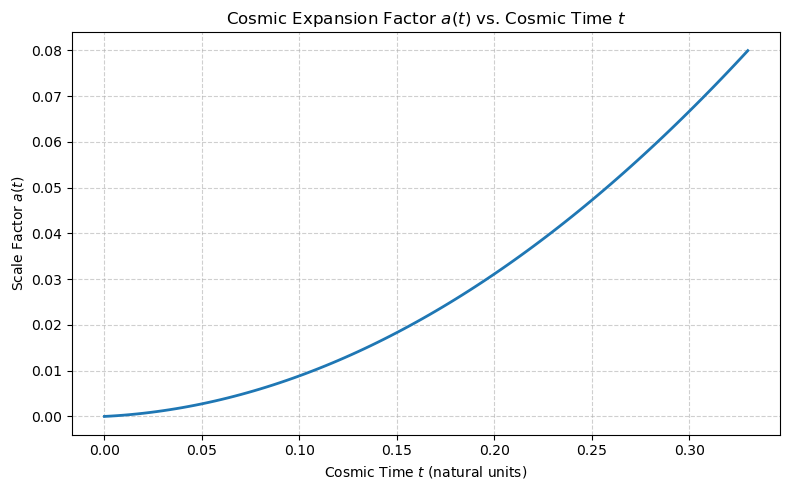

In [7]:
# Solve for a(t) across 100 equally spaced values of t in [0, 0.33]
t_vals = np.linspace(0.0, 0.33, 100)
a_vals = np.zeros_like(t_vals)

for i, t_target in enumerate(t_vals):
    if t_target == 0.0:
        a_vals[i] = 0.0
    else:
        f = lambda a: quad(integrand, 0.0, a, epsabs=1e-13, epsrel=1e-13)[0] - t_target
        df = lambda a: integrand(a)
        # Warm-start with previous root and tighten lower bracket for speed
        lower_bound = a_vals[i - 1]
        a_vals[i], _ = newton_bracketed(f, df, lower_bound, 1.0)

# Plot a vs. t
plt.figure(figsize=(8, 5))
plt.plot(t_vals, a_vals, linewidth=2, color="#1f77b4", label=r"$a(t)$")
plt.xlabel("Cosmic Time $t$ (natural units)")
plt.ylabel("Scale Factor $a(t)$")
plt.title("Cosmic Expansion Factor $a(t)$ vs. Cosmic Time $t$")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()